# DWT–DCT Digital Image Watermarking — v5 (Improved)

This is a revised version of the original ADIP project. It keeps the same core idea —
embedding a binary watermark into the DCT coefficients of a wavelet sub-band — but fixes
the bug that was making extraction inaccurate, and adds proper evaluation.

**What changed from v4.3, and why:**

1. **Root-cause fix — watermark capacity bug.** The old code always decomposed the cover
   image with `level=3` wavelet decomposition *and then* split the resulting sub-band into
   8×8 DCT blocks. For a 512×512 image that leaves only an **8×8 = 64-bit** watermark —
   any logo or text resized down to 8×8 pixels is unrecognizable, no matter how strong the
   embedding is. This was the real reason extraction looked wrong. Lowering the decomposition
   level (default now `level=1`) gives **32×32 = 1024 bits**, enough to actually recognize
   the recovered watermark. The trade-off (capacity vs. robustness) is now a variable you
   control and can see the effect of directly.
2. **Generalized the block/sub-band math.** The old code hardcoded `// 8` twice (once for
   the sub-band size, once for the DCT block size), which only worked because it happened to
   match `level=3`. It's now computed from `2**level` and a configurable `BLOCK_SIZE`, so it
   is correct for any level you choose.
3. **Reflect padding instead of zero padding.** Zero-padding creates a hard black edge that
   injects spurious high-frequency energy into the wavelet decomposition near the border.
   Padding now mirrors the image edge instead, and the final image is cropped back to the
   original size before saving.
4. **Real accuracy metrics.** Bit Error Rate (BER) and Normalized Correlation (NC) between
   the embedded and extracted watermark bit-maps, not just a visual comparison of the cover
   image.
5. **Robustness testing.** JPEG re-compression, Gaussian noise, and median-blur attacks, with
   BER/NC reported for each, so you can see how the scheme degrades — useful for the
   discussion section of a report.
6. **Default sample images bundled + your own images supported.** No required downloads —
   a default cover/watermark pair is generated locally so the notebook always runs. You can
   swap in your own two images with one flag.


## 1. Setup — Import Libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pywt
import pandas as pd
from skimage.metrics import structural_similarity as ssim
from skimage import data as skdata


## 2. Utility Functions

In [2]:
def show_images(images, titles=None, cmap='gray', figsize=(15, 6)):
    plt.figure(figsize=figsize)
    for i in range(len(images)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(images[i], cmap=cmap)
        if titles is not None:
            plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()


**`binarize_watermark`** — unchanged from the original: threshold a grayscale watermark
into a 0/1 bit-map.

In [3]:
def binarize_watermark(wm_gray):
    _, binary = cv2.threshold(wm_gray, 127, 1, cv2.THRESH_BINARY)
    return binary.astype(np.uint8)


**`pad_to_multiple_of_2n`** — *fixed*: now uses reflect padding (`cv2.BORDER_REFLECT101`)
instead of zero padding, which avoids injecting a hard black edge into the wavelet
decomposition. `crop_to_shape` restores the original dimensions afterwards.

In [4]:
def pad_to_multiple_of_2n(image, n):
    multiple = 2 ** n
    h, w = image.shape
    new_h = ((h + multiple - 1) // multiple) * multiple
    new_w = ((w + multiple - 1) // multiple) * multiple
    pad_h, pad_w = new_h - h, new_w - w
    if pad_h == 0 and pad_w == 0:
        return image.copy()
    return cv2.copyMakeBorder(image, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT101)

def crop_to_shape(image, shape):
    h, w = shape
    return image[:h, :w]


**New — `watermark_accuracy`**: quantitative comparison of the embedded vs. extracted
bit-maps.

- **BER** (Bit Error Rate): fraction of bits that flipped. Lower is better, 0 is perfect.
- **NC** (Normalized Correlation): standard watermarking-literature metric, 1.0 is a perfect
  match, ~0 is uncorrelated (random guessing).

In [5]:
def watermark_accuracy(original_bits, extracted_bits):
    o = original_bits.astype(np.int32)
    e = extracted_bits.astype(np.int32)
    ber = np.mean(o != e)
    o_pm, e_pm = np.where(o == 1, 1.0, -1.0), np.where(e == 1, 1.0, -1.0)
    nc = float(np.sum(o_pm * e_pm) / (np.sqrt(np.sum(o_pm**2)) * np.sqrt(np.sum(e_pm**2))))
    return {"BER": ber, "NC": nc, "Accuracy_%": (1 - ber) * 100}


## 3. Choose Your Images — Default Samples or Your Own

Set `USE_DEFAULT_IMAGES = False` and fill in the two paths below to use your own
cover and watermark images instead of the bundled defaults.

- **In Colab**: upload your files with the file browser on the left (or run
  `from google.colab import files; files.upload()` in a new cell), then set the paths to
  match the uploaded filenames.
- **In local Jupyter**: just point the paths at files on disk.

The defaults need no internet connection or download — they're generated locally so the
notebook always runs end-to-end on a fresh machine.

In [6]:
USE_DEFAULT_IMAGES = True   # set to False to use your own images

CUSTOM_COVER_PATH = ""      # e.g. "my_photo.jpg"  (used only if USE_DEFAULT_IMAGES = False)
CUSTOM_WATERMARK_PATH = ""  # e.g. "my_logo.png"


Using bundled default sample images (cover + watermark).


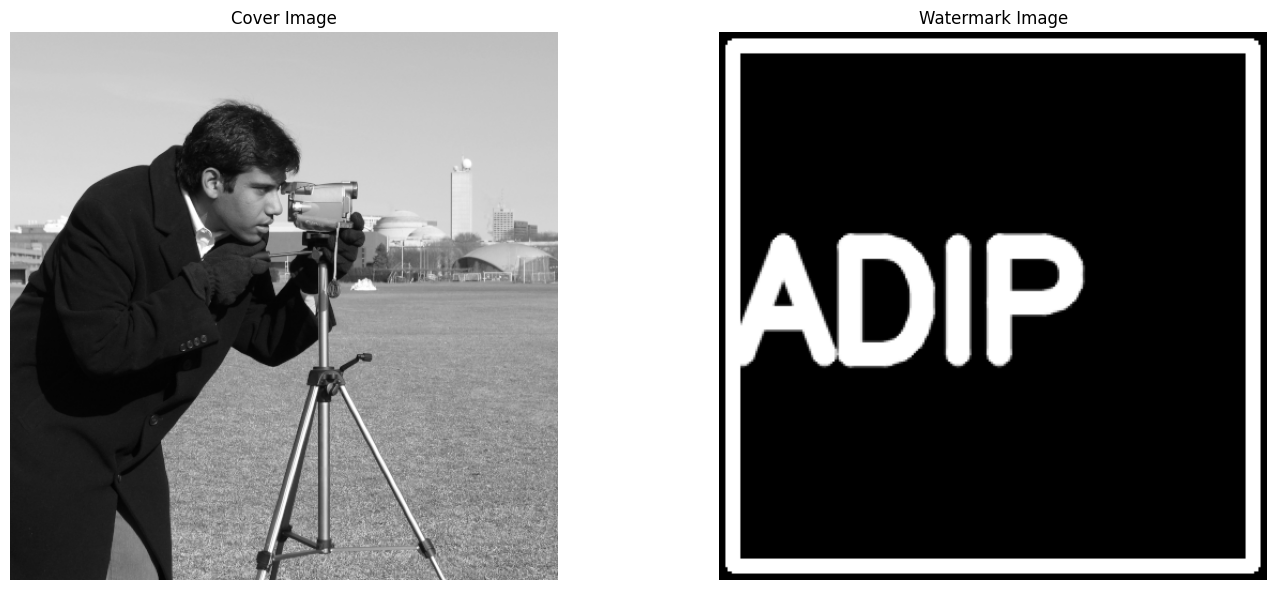

Cover size: (512, 512)  Watermark size: (256, 256)


In [7]:
def make_default_cover():
    # scikit-image ships this classic 512x512 grayscale test image locally — no download needed
    return skdata.camera()

def make_default_watermark():
    wm = np.zeros((256, 256), dtype=np.uint8)
    cv2.putText(wm, "ADIP", (8, 150), cv2.FONT_HERSHEY_SIMPLEX, 2.4, 255, 10, cv2.LINE_AA)
    cv2.rectangle(wm, (6, 6), (249, 249), 255, 6)
    return wm

if USE_DEFAULT_IMAGES:
    orig_cover = make_default_cover()
    wm_gray = make_default_watermark()
    print("Using bundled default sample images (cover + watermark).")
else:
    assert CUSTOM_COVER_PATH and CUSTOM_WATERMARK_PATH, \
        "Set CUSTOM_COVER_PATH and CUSTOM_WATERMARK_PATH above, or switch USE_DEFAULT_IMAGES back to True."
    orig_cover = cv2.imread(CUSTOM_COVER_PATH, cv2.IMREAD_GRAYSCALE)
    wm_gray = cv2.imread(CUSTOM_WATERMARK_PATH, cv2.IMREAD_GRAYSCALE)
    assert orig_cover is not None, f"Could not read cover image at '{CUSTOM_COVER_PATH}'"
    assert wm_gray is not None, f"Could not read watermark image at '{CUSTOM_WATERMARK_PATH}'"
    print(f"Using custom images: {CUSTOM_COVER_PATH}, {CUSTOM_WATERMARK_PATH}")

show_images([orig_cover, wm_gray], ['Cover Image', 'Watermark Image'])
print("Cover size:", orig_cover.shape, " Watermark size:", wm_gray.shape)


## 4. Embed Watermark (DWT + block DCT)

**Fixed**: the sub-band size and block-count math is now derived from `2**level` and
`BLOCK_SIZE` instead of a hardcoded `// 8` (which only happened to be correct for
`level=3`). This is the same function shape as before, just generalized and correctly
parametrized.

One clarification on naming: `pywt.wavedec2`'s `cH` (returned first in the detail tuple) is
the sub-band with horizontal detail — conventionally called **LH**, not **HL** as the
original comments said. This doesn't change how the code runs, just how you should describe
it in your report.

In [8]:
BLOCK_SIZE = 8  # standard DCT block size

def embed_watermark(cover_gray, wm_bin, level=1, alpha=40, block_size=BLOCK_SIZE):
    coeffs = pywt.wavedec2(cover_gray, 'haar', level=level)
    cA = coeffs[0]
    cH, cV, cD = coeffs[1]   # cH = LH (horizontal detail) sub-band at the coarsest level

    LH = cH.copy().astype(np.float32)
    Hh, Hw = LH.shape
    n_blocks_vert = Hh // block_size
    n_blocks_horz = Hw // block_size

    if wm_bin.shape != (n_blocks_vert, n_blocks_horz):
        raise ValueError(
            f"Watermark bit-map must be exactly {n_blocks_vert}x{n_blocks_horz} "
            f"for level={level}, block_size={block_size}."
        )

    for by in range(n_blocks_vert):
        for bx in range(n_blocks_horz):
            y0, x0 = by * block_size, bx * block_size
            block = LH[y0:y0 + block_size, x0:x0 + block_size].copy()
            dct_block = cv2.dct(block)
            dct_block[3, 3] = alpha if wm_bin[by, bx] == 1 else -alpha
            LH[y0:y0 + block_size, x0:x0 + block_size] = cv2.idct(dct_block)

    coeffs_mod = [cA, (LH, cV, cD)] + coeffs[2:]
    rec = pywt.waverec2(coeffs_mod, 'haar')
    return np.clip(rec, 0, 255).astype(np.uint8)


## 5. Extract Watermark

**Fixed** the same way as embedding, so the block grid always matches what was embedded.

In [9]:
def extract_watermark_from_LH(watermarked_gray, level=1, block_size=BLOCK_SIZE):
    coeffs_wm = pywt.wavedec2(watermarked_gray.astype(np.float32), 'haar', level=level)
    cH_wm, cV_wm, cD_wm = coeffs_wm[1]
    LH_wm = cH_wm.copy().astype(np.float32)

    Hh, Hw = LH_wm.shape
    n_blocks_vert = Hh // block_size
    n_blocks_horz = Hw // block_size

    recovered = np.zeros((n_blocks_vert, n_blocks_horz), dtype=np.uint8)
    for by in range(n_blocks_vert):
        for bx in range(n_blocks_horz):
            y0, x0 = by * block_size, bx * block_size
            block = LH_wm[y0:y0 + block_size, x0:x0 + block_size]
            dct_block = cv2.dct(block)
            recovered[by, bx] = 1 if dct_block[3, 3] >= 0 else 0
    return recovered


## 6. Visualize Wavelet Sub-bands

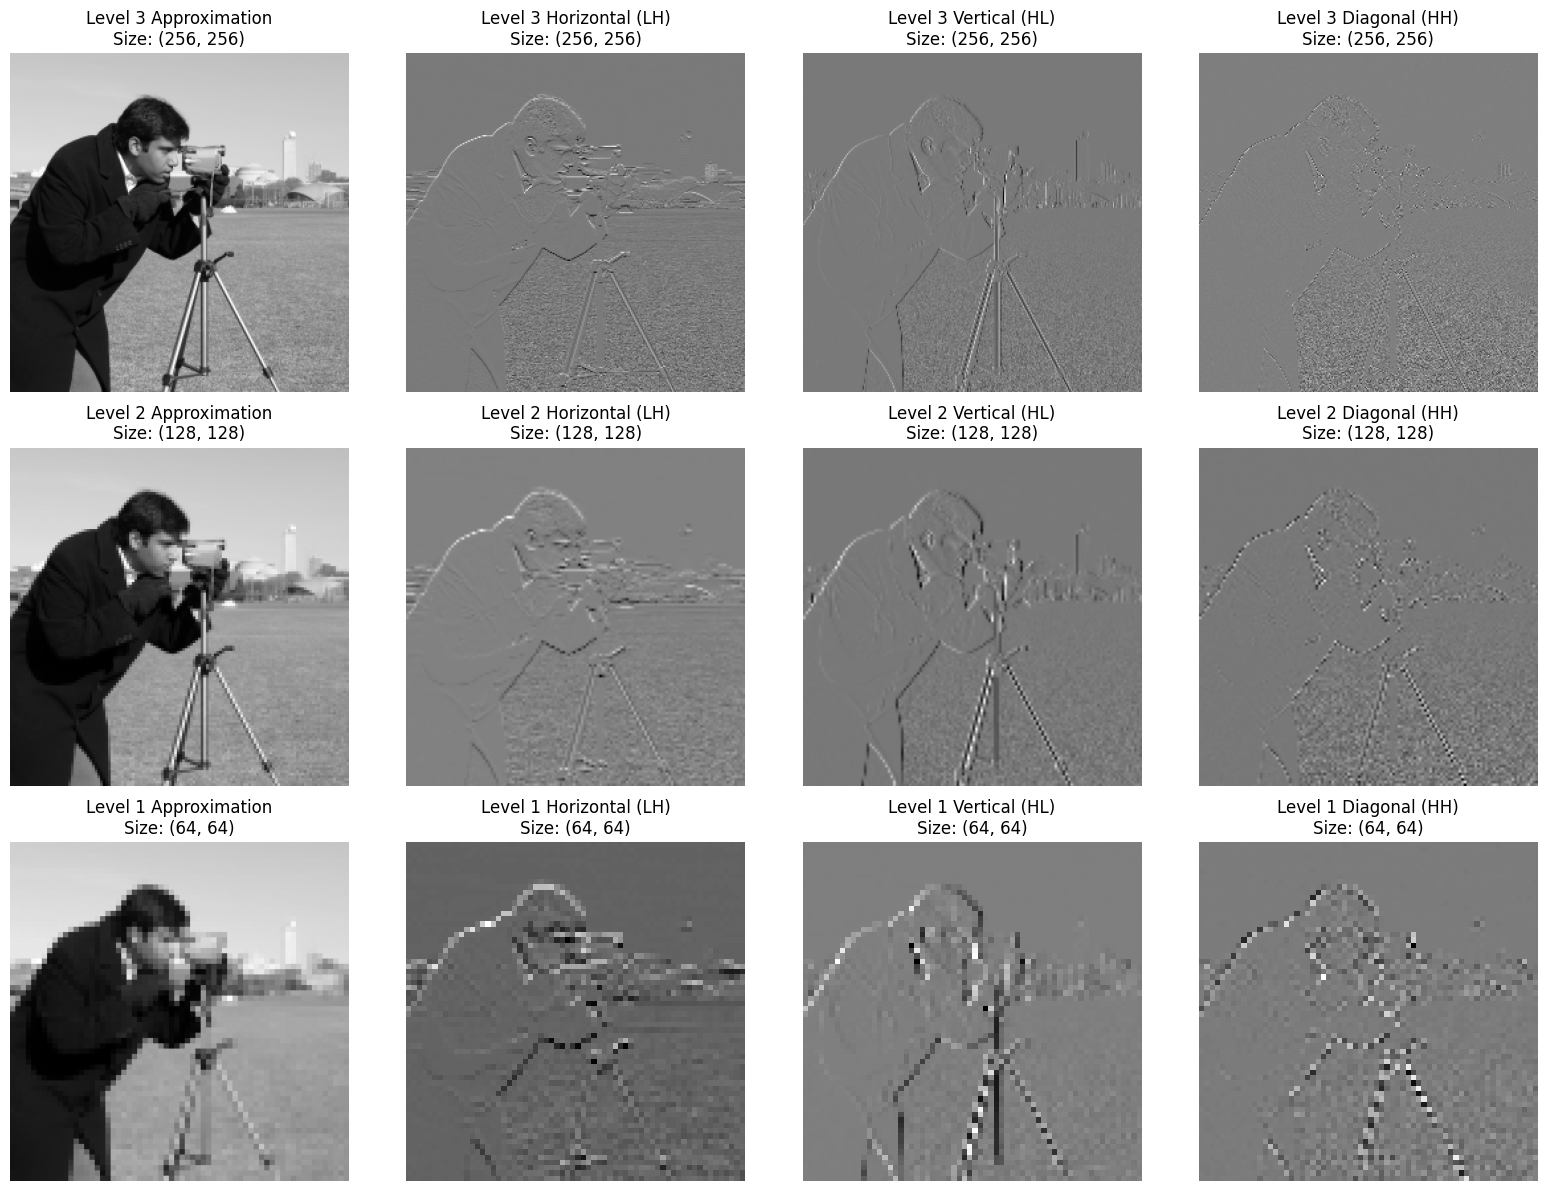

In [10]:
def visualize_all_subbands(padded_img, wavelet='haar', level=3):
    coeffs = pywt.wavedec2(padded_img, wavelet=wavelet, level=level)
    total_levels = len(coeffs) - 1
    fig, axes = plt.subplots(total_levels, 4, figsize=(16, 4 * total_levels))
    if total_levels == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(total_levels):
        lvl = total_levels - i
        new_coeffs = [coeffs[0] if j == 0 else (None, None, None) for j in range(len(coeffs))]
        for j in range(1, lvl):
            new_coeffs[j] = coeffs[j]
        approx_img = pywt.waverec2(new_coeffs, wavelet)

        approx_shape = coeffs[0].shape
        for _ in range(1, lvl):
            approx_shape = tuple(s * 2 for s in approx_shape)

        cH, cV, cD = coeffs[lvl]
        axes[i, 0].imshow(approx_img, cmap='gray'); axes[i, 0].set_title(f'Level {lvl} Approximation\nSize: {approx_shape}')
        axes[i, 1].imshow(cH, cmap='gray'); axes[i, 1].set_title(f'Level {lvl} Horizontal (LH)\nSize: {cH.shape}')
        axes[i, 2].imshow(cV, cmap='gray'); axes[i, 2].set_title(f'Level {lvl} Vertical (HL)\nSize: {cV.shape}')
        axes[i, 3].imshow(cD, cmap='gray'); axes[i, 3].set_title(f'Level {lvl} Diagonal (HH)\nSize: {cD.shape}')
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout()
    plt.show()

visualize_all_subbands(orig_cover.astype(np.float32), wavelet='haar', level=3)


## 7. Why the Old Version Looked Inaccurate — Before/After Demo

This cell embeds and extracts the **same** watermark twice on your loaded images —
once with the old default (`level=3`) and once with the fixed default (`level=1`) — so you
can see the capacity difference directly, on your own data.

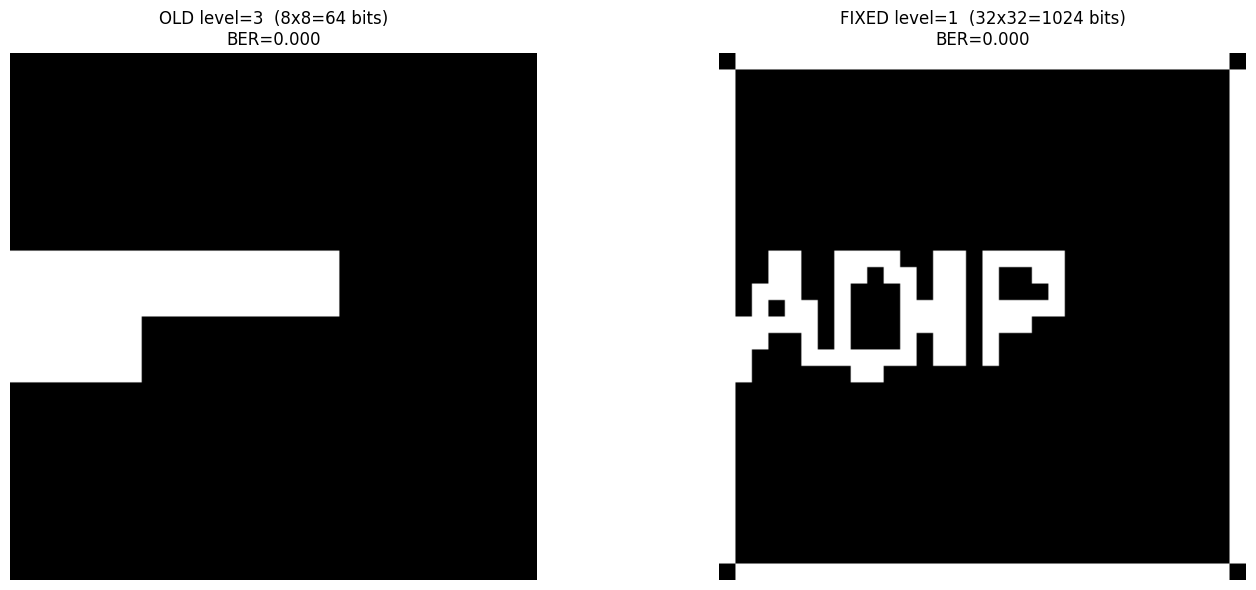

Bit error rate is near 0 in BOTH cases — the old version was never failing to decode
its bits correctly. It was failing because it only ever had 64 bits to work with.


In [11]:
def run_capacity_demo(cover, wm, level, alpha=40, wavelet_pad_level=3):
    padded = pad_to_multiple_of_2n(cover.astype(np.float32), max(level, wavelet_pad_level))
    H_pad, W_pad = padded.shape
    HL_h, HL_w = H_pad // (2 ** level), W_pad // (2 ** level)
    blocks_v, blocks_h = HL_h // BLOCK_SIZE, HL_w // BLOCK_SIZE
    wm_resized = cv2.resize(wm, (blocks_h, blocks_v), interpolation=cv2.INTER_AREA)
    wm_bin = binarize_watermark(wm_resized)
    watermarked = embed_watermark(padded, wm_bin, level=level, alpha=alpha)
    recovered = extract_watermark_from_LH(watermarked, level=level)
    metrics = watermark_accuracy(wm_bin, recovered)
    return blocks_v, blocks_h, recovered, metrics

bv3, bh3, rec3, m3 = run_capacity_demo(orig_cover, wm_gray, level=3)
bv1, bh1, rec1, m1 = run_capacity_demo(orig_cover, wm_gray, level=1)

show_images(
    [cv2.resize(rec3 * 255, (256, 256), interpolation=cv2.INTER_NEAREST),
     cv2.resize(rec1 * 255, (256, 256), interpolation=cv2.INTER_NEAREST)],
    titles=[f'OLD level=3  ({bv3}x{bh3}={bv3*bh3} bits)\nBER={m3["BER"]:.3f}',
            f'FIXED level=1  ({bv1}x{bh1}={bv1*bh1} bits)\nBER={m1["BER"]:.3f}']
)
print("Bit error rate is near 0 in BOTH cases — the old version was never failing to decode")
print("its bits correctly. It was failing because it only ever had 64 bits to work with.")


## 8. Run the Full Pipeline — Configure, Pad, Resize Watermark, Embed

Padded cover: (512, 512)  ->  watermark capacity: 32x32 = 1024 bits


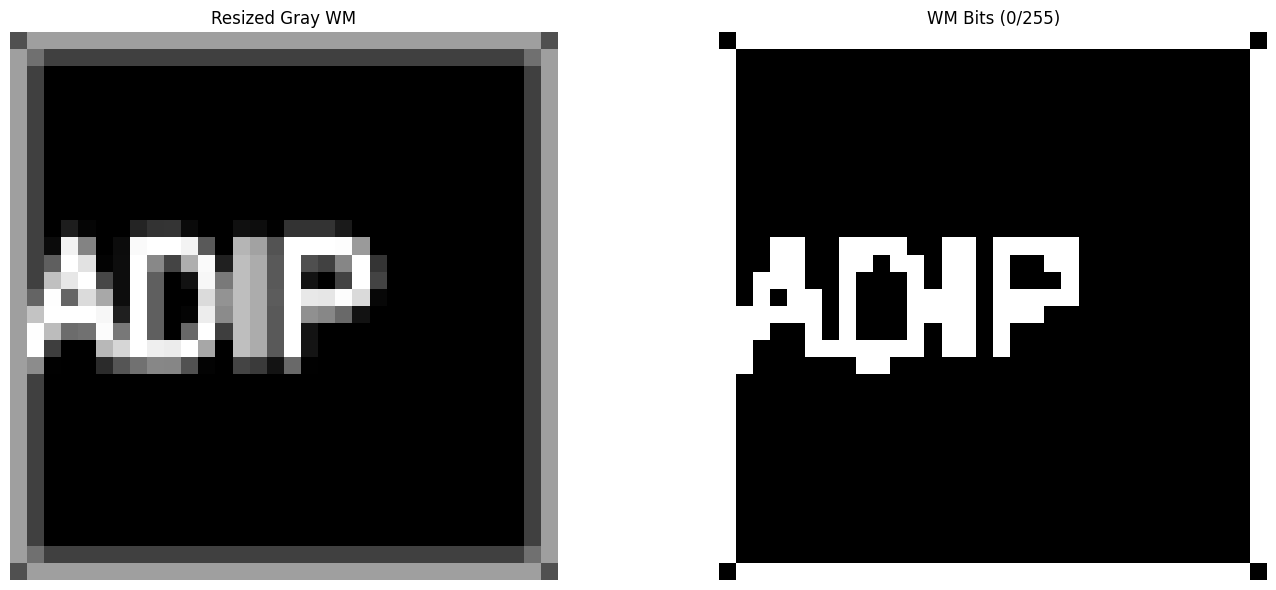

In [12]:
LEVEL = 1     # wavelet decomposition level -> lower = higher watermark resolution, less robust
ALPHA = 40    # embedding strength -> higher = more robust, more visible distortion

cover_f = orig_cover.astype(np.float32)
padded_cover = pad_to_multiple_of_2n(cover_f, LEVEL)
H_pad, W_pad = padded_cover.shape

HL_h, HL_w = H_pad // (2 ** LEVEL), W_pad // (2 ** LEVEL)
blocks_vertical = HL_h // BLOCK_SIZE
blocks_horizontal = HL_w // BLOCK_SIZE
print(f"Padded cover: {padded_cover.shape}  ->  watermark capacity: "
      f"{blocks_vertical}x{blocks_horizontal} = {blocks_vertical*blocks_horizontal} bits")

wm_resized = cv2.resize(wm_gray, (blocks_horizontal, blocks_vertical), interpolation=cv2.INTER_AREA)
wm_bin = binarize_watermark(wm_resized)
show_images([wm_resized, wm_bin * 255], titles=['Resized Gray WM', 'WM Bits (0/255)'])


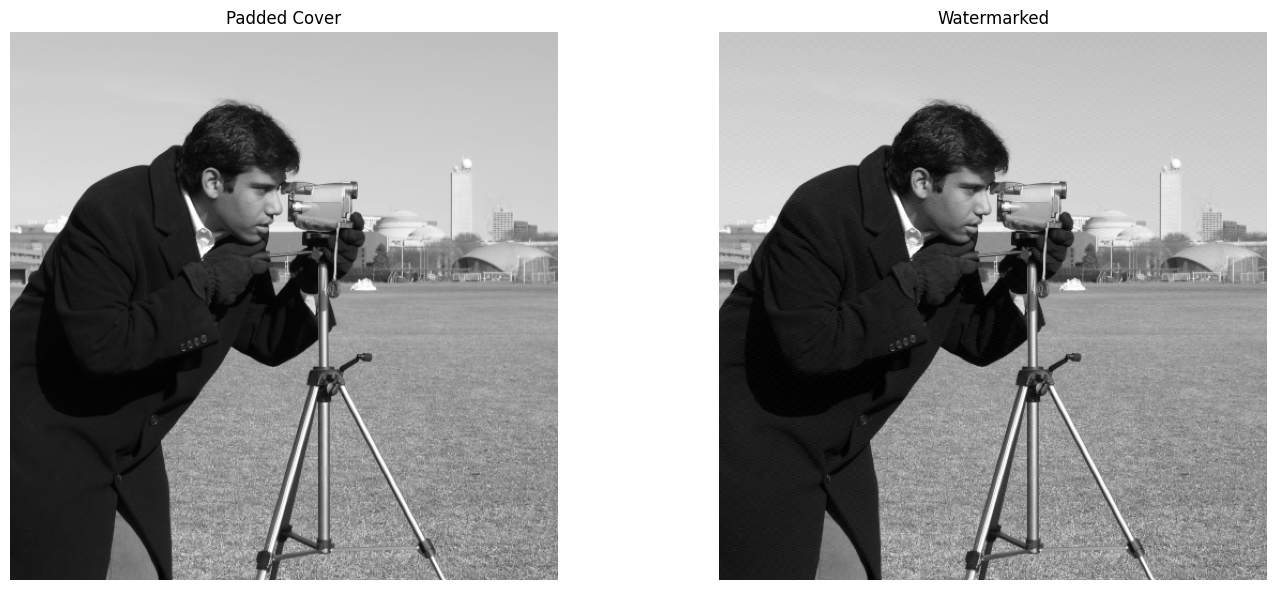

In [13]:
watermarked = embed_watermark(padded_cover, wm_bin, level=LEVEL, alpha=ALPHA)
show_images([padded_cover.astype(np.uint8), watermarked], titles=['Padded Cover', 'Watermarked'])


## 9. Compare Original vs Watermarked Cover

In [14]:
def compare_images(original, watermarked):
    original_f = original.astype(np.float32)
    watermarked_f = watermarked.astype(np.float32)
    mse_val = np.mean((original_f - watermarked_f) ** 2)
    psnr_val = cv2.PSNR(original.astype(np.uint8), watermarked.astype(np.uint8))
    ssim_val = ssim(original.astype(np.uint8), watermarked.astype(np.uint8),
                     data_range=255)
    print(f"MSE:  {mse_val:.4f}")
    print(f"PSNR: {psnr_val:.2f} dB   (higher is better; >35 dB is typically imperceptible)")
    print(f"SSIM: {ssim_val:.4f}   (closer to 1.0 is better)")
    return {"MSE": mse_val, "PSNR": psnr_val, "SSIM": ssim_val}

_ = compare_images(padded_cover, watermarked)


MSE:  6.7795
PSNR: 39.82 dB   (higher is better; >35 dB is typically imperceptible)
SSIM: 0.9463   (closer to 1.0 is better)


## 10. Extract & Evaluate Watermark Accuracy

This is the check the original notebook was missing: not just *does the pipeline run*,
but *how close is the extracted watermark to what was embedded*, measured with BER and NC.

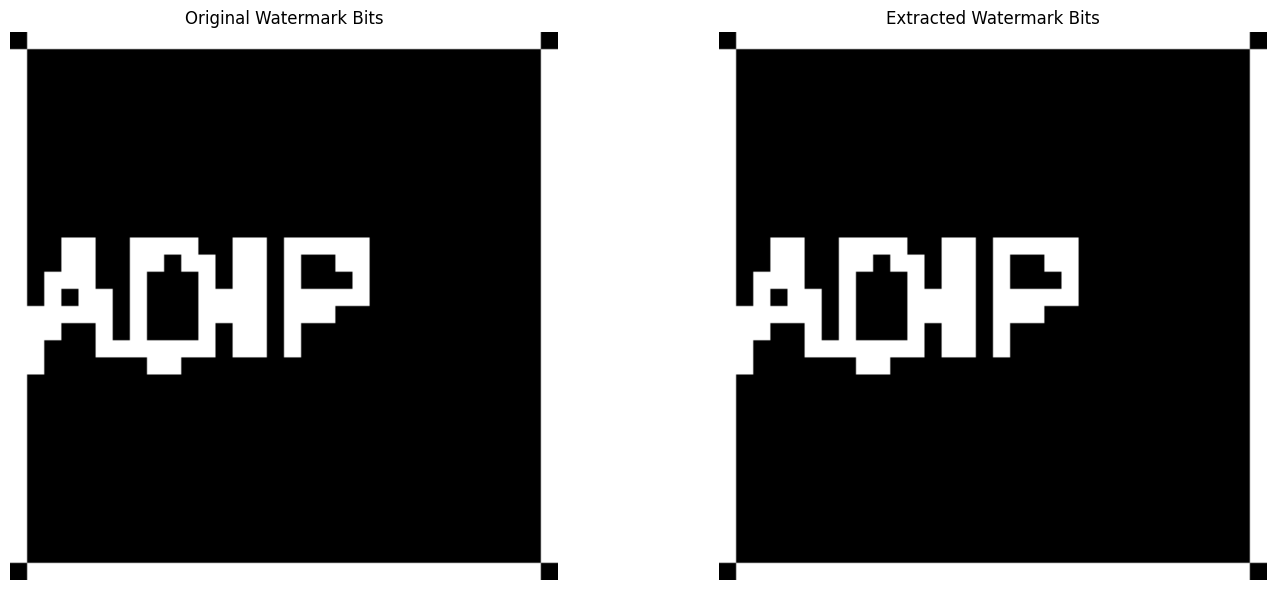

BER: 0.0000   NC: 1.0000   Accuracy: 100.00%


In [15]:
recovered = extract_watermark_from_LH(watermarked, level=LEVEL)

display_size = (256, 256)
show_images(
    [cv2.resize(wm_bin * 255, display_size, interpolation=cv2.INTER_NEAREST),
     cv2.resize(recovered * 255, display_size, interpolation=cv2.INTER_NEAREST)],
    titles=['Original Watermark Bits', 'Extracted Watermark Bits']
)

metrics = watermark_accuracy(wm_bin, recovered)
print(f"BER: {metrics['BER']:.4f}   NC: {metrics['NC']:.4f}   Accuracy: {metrics['Accuracy_%']:.2f}%")


## 11. Robustness Testing — How Well Does It Survive Common Attacks?

A watermark that only survives an untouched image isn't very useful. This section
re-extracts the watermark after common real-world distortions and reports BER/NC for each,
so you can discuss the robustness/capacity trade-off with actual numbers.

In [16]:
def jpeg_attack(img, quality):
    ok, enc = cv2.imencode('.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return cv2.imdecode(enc, cv2.IMREAD_GRAYSCALE)

def noise_attack(img, sigma):
    noise = np.random.normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def blur_attack(img, ksize):
    return cv2.medianBlur(img, ksize)

attacks = {
    "No attack": lambda img: img,
    "JPEG Q=90": lambda img: jpeg_attack(img, 90),
    "JPEG Q=70": lambda img: jpeg_attack(img, 70),
    "JPEG Q=50": lambda img: jpeg_attack(img, 50),
    "Gaussian noise (sigma=5)": lambda img: noise_attack(img, 5),
    "Gaussian noise (sigma=15)": lambda img: noise_attack(img, 15),
    "Median blur (3x3)": lambda img: blur_attack(img, 3),
}

rows = []
for name, fn in attacks.items():
    attacked = fn(watermarked)
    rec = extract_watermark_from_LH(attacked, level=LEVEL)
    m = watermark_accuracy(wm_bin, rec)
    rows.append({"Attack": name, "BER": round(m["BER"], 4),
                 "NC": round(m["NC"], 4), "Accuracy_%": round(m["Accuracy_%"], 2)})

results_df = pd.DataFrame(rows)
results_df


,Attack,BER,NC,Accuracy_%
0,No attack,0.0000,1.0000,100.00
1,JPEG Q=90,0.0000,1.0000,100.00
2,JPEG Q=70,0.0156,0.9688,98.44
3,JPEG Q=50,0.2852,0.4297,71.48
4,Gaussian noise (sigma=5),0.0000,1.0000,100.00
5,Gaussian noise (sigma=15),0.0029,0.9941,99.71
6,Median blur (3x3),0.5059,-0.0117,49.41


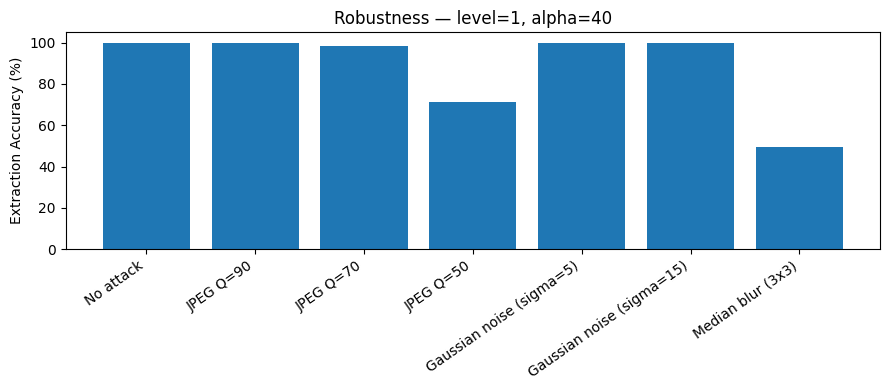

In [17]:
plt.figure(figsize=(9, 4))
plt.bar(results_df["Attack"], results_df["Accuracy_%"])
plt.ylabel("Extraction Accuracy (%)")
plt.title(f"Robustness — level={LEVEL}, alpha={ALPHA}")
plt.xticks(rotation=35, ha='right')
plt.ylim(0, 105)
plt.tight_layout()
plt.show()


**Reading these results:** `level=1` gives much better *resolution* but is more fragile
under attack, because the finest wavelet detail is the first thing compression and blurring
destroy. If robustness against JPEG/noise matters more than watermark resolution for your use
case, try `LEVEL = 2` or `LEVEL = 3` in Section 8 and re-run — you'll trade recognizability for
survivability. Increasing `ALPHA` also improves robustness at the cost of visible distortion
(watch the PSNR/SSIM in Section 9).

## 12. Save the Final Watermarked Image

Saved: watermarked_output.png  (size: (512, 512))


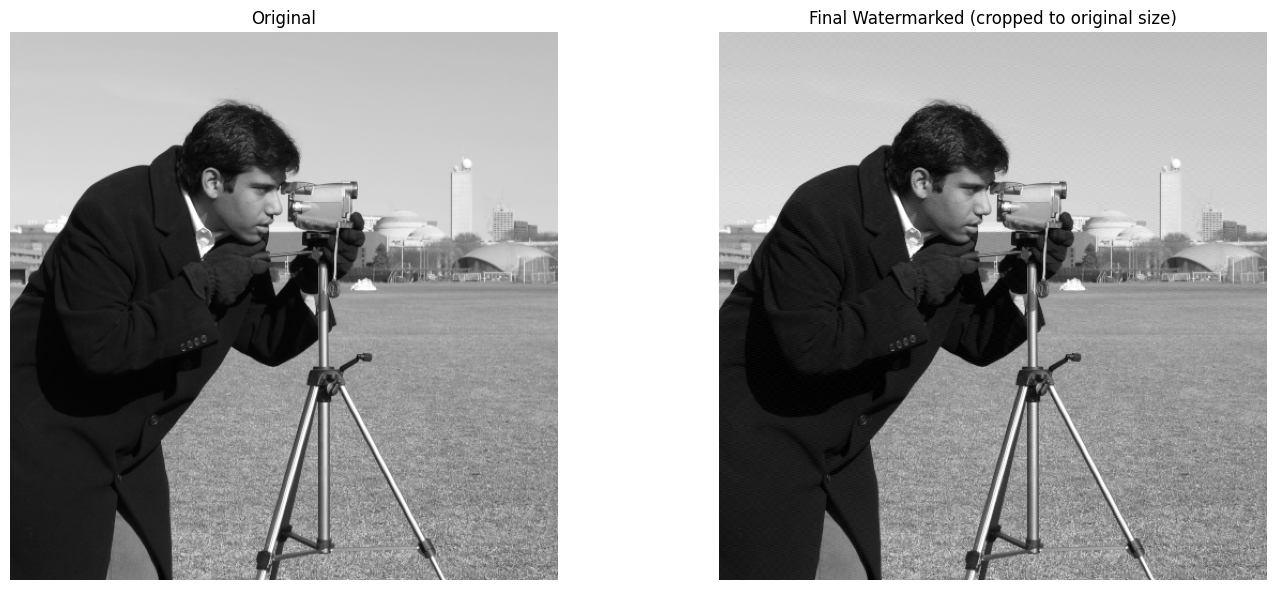

In [18]:
final_watermarked = crop_to_shape(watermarked, orig_cover.shape)
out_path = "watermarked_output.png"
cv2.imwrite(out_path, final_watermarked)
print(f"Saved: {out_path}  (size: {final_watermarked.shape})")
show_images([orig_cover, final_watermarked], titles=['Original', 'Final Watermarked (cropped to original size)'])


## Summary

| | Old (v4.3) | New (v5) |
|---|---|---|
| Default watermark capacity (512×512 cover) | 64 bits (8×8) | 1024 bits (32×32) |
| Sub-band/block math | hardcoded for level=3 only | generalized for any level |
| Padding | zero-padding (hard edge) | reflect padding, cropped back after |
| Accuracy evaluation | visual only, cover image only | BER + NC on the watermark itself |
| Robustness | untested | JPEG / noise / blur attack suite |
| Sample images | required a Google Drive download | bundled offline defaults + custom upload option |

**Ideas for further improvement**, if you want to keep pushing this:
- Make `alpha` adaptive per-block (scale with local coefficient energy) instead of a fixed
  constant, to hide more strength in busy/textured regions.
- Extend to color images by embedding only in the Y channel of YCrCb and leaving color
  channels untouched.
- Add a cropping/rotation attack and a simple synchronization scheme, since geometric attacks
  are the classic failure mode for block-based watermarking.
